<div class="alert alert-block alert-info"><b>This notebook is an introduction to this project, as well as a description of the data and its parameters before we get to use it for astronomical analysis.</b></div>

## Stellar Evolution Through Gaia DR3 - A Data Driven Analysis of 50,000 Stars
### Author
Sania Latifi
#### Introduction
The aim of this project was to apply my data analysis skills to the visualization and exploration of stellar data using Hertzsprung-Russell (HR) diagrams. The astronomical concepts and interpretations presented throughout this notebook are based on astronomy books I have studied, alongside additional research conducted during the development of the project. This project was developed as an academic data-analysis portfolio project demonstrating experience with astronomical survey data, scientific computing, statistical analysis, and data visualization.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
stars = pd.read_csv('stellar_population_analysis-result.csv', sep=',')
stars.sample(5)

,source_id,random_index,ra,dec,parallax,parallax_error,phot_g_mean_mag,phot_bp_mean_mag,phot_rp_mean_mag,bp_rp,teff_gspphot,lum_flame,radius_flame,mass_flame,age_flame
15171,1743166975923404288,454407,318.491202,8.759849,0.941221,0.093380,17.379953,18.113297,16.575619,1.537678,4131.6514,0.129329,0.694014,0.649497,4.635569
43908,6237163125145309824,1326082,239.516103,-23.157014,0.898722,0.066390,16.652890,17.148310,15.996938,1.151372,4739.5790,0.229157,0.711734,0.764963,3.304184
37199,478936068086195456,1123618,72.522899,63.678746,0.381491,0.034582,15.795357,16.215450,15.189450,1.026000,6567.7650,4.649947,1.658849,1.372430,2.177952
27667,5923330891316662016,832244,259.676210,-53.350364,0.505555,0.033020,15.023212,15.421166,14.443546,0.977620,5838.9150,3.486289,1.831988,1.151153,6.279580
20109,5983686043814650368,605532,242.525084,-48.943725,0.519674,0.047114,16.086777,17.040830,15.107157,1.933674,8294.3480,19.191553,2.104487,1.954852,0.679999


In [3]:
print(f"Number of stars: {stars.shape[0]:,}")
print(f"Number of variables: {stars.shape[1]}")

Number of stars: 50,000
Number of variables: 15


In [4]:
stars.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   source_id         50000 non-null  int64  
 1   random_index      50000 non-null  int64  
 2   ra                50000 non-null  float64
 3   dec               50000 non-null  float64
 4   parallax          50000 non-null  float64
 5   parallax_error    50000 non-null  float64
 6   phot_g_mean_mag   50000 non-null  float64
 7   phot_bp_mean_mag  50000 non-null  float64
 8   phot_rp_mean_mag  50000 non-null  float64
 9   bp_rp             50000 non-null  float64
 10  teff_gspphot      50000 non-null  float64
 11  lum_flame         50000 non-null  float64
 12  radius_flame      50000 non-null  float64
 13  mass_flame        50000 non-null  float64
 14  age_flame         50000 non-null  float64
dtypes: float64(13), int64(2)
memory usage: 5.7 MB


### Dataset Parameters and Their Physcial Meaning
|Parameter|Description|
|---------|-----------|
|```source_id```|Unique identifier assigned to each astronomical source by Gaia.|
|```rabdom_index```|Random index used to obtain a representative subset of Gaia sources.|
|```ra```|Right Ascension, describing the star's position on the sky.|
|```dec```|Declination, describing the star's position north or south of the celestial equator|
|```parallax```|Apparent angular shift of a star caused by Earth's orbit, used to estimate its distance.|
|```parallax_error```|Uncertainty associated with the measured parallax.|
|```phot_g_mean_mag```|Mean apparent brightness of the star measured in Gaia's broad G band.|
|```phot_bp_mean_mag```|Mean apparent brightness measured in Gaia's blue photometric band.|
|```phot_rp_mean_mag```|Mean apparent brightness measured in Gaia's red photometric band.|
|```bp_rp```|Difference between BP and RP magnitudes, providing a measure of stellar color.|
|```teff_gspphot```|Estimated effective temperature of the star's surface, measured in Kelvin.|
|```lum_flame```|Estimated stellar luminosity relative to the Sun.|
|```radius_flame```|Estimated stellar radius relative to the Sun.|
|```mass_flame```|Estimated stellar mass relative to the Sun.|
|```age_flame```|Estimated age of the star, derived from stellar evolution models.|

#### Observed quantities measured by Gaia:
- Ra/Dec
- Parallax
- Magnitudes
- BP/RP color
#### Derived parameteres:
- Temperature
- Luminosity
- Radius
- Mass
- Age

The original query I used on the gaia website specifically requested non-null values. But just checking to make sure:

In [5]:
stars.isnull().sum()

source_id           0
random_index        0
ra                  0
dec                 0
parallax            0
parallax_error      0
phot_g_mean_mag     0
phot_bp_mean_mag    0
phot_rp_mean_mag    0
bp_rp               0
teff_gspphot        0
lum_flame           0
radius_flame        0
mass_flame          0
age_flame           0
dtype: int64

Before making our important visualizations, we need to understand the population we're working with. I chose to create a plot that depicts **the distribution of stellar effective temperatures** to check a few boxes:
- Are most of the stars relatively cool?
- Do we have a reasonable number of extremely hot stars?
- Are there unusual values that might imply data quality problems?
- Is the distribution heavily concentrated in a particular temperature range?
- Anything unexpected worth investigating?

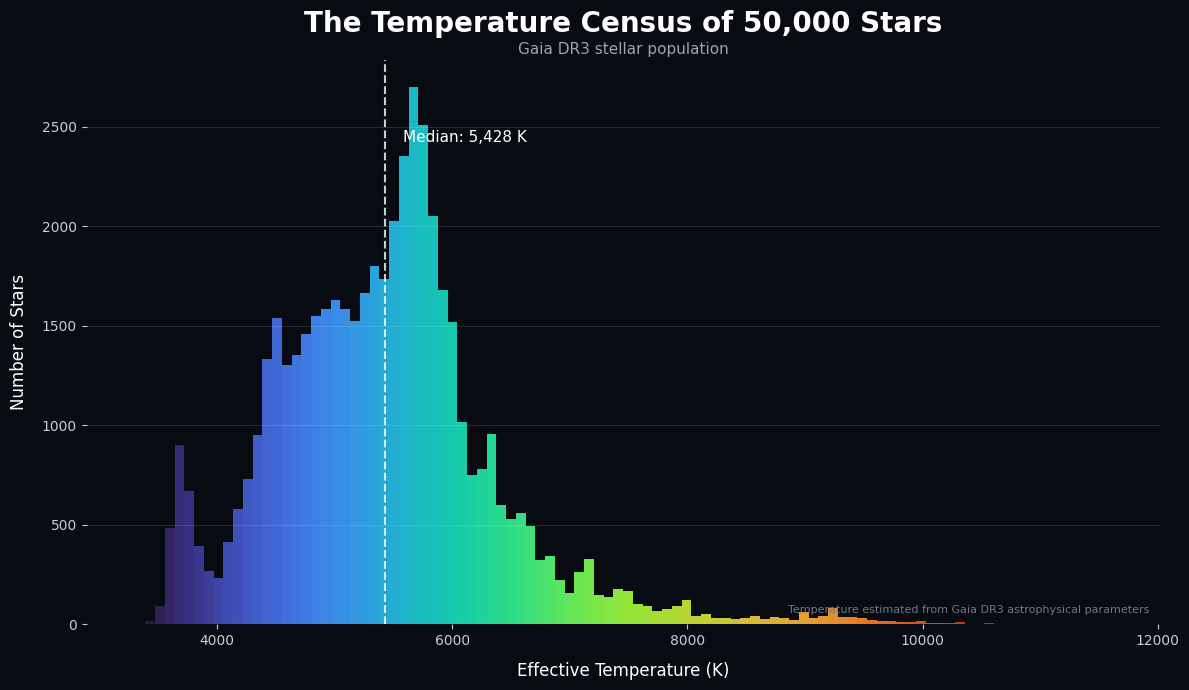

In [6]:
temperature = stars["teff_gspphot"].dropna()

fig, ax = plt.subplots(figsize=(12, 7))

fig.patch.set_facecolor("#080b12")
ax.set_facecolor("#080b12")

counts, bins, patches = ax.hist(
    temperature,
    bins=100,
    edgecolor="none",
    alpha=0.9
)


cmap = plt.cm.turbo
norm = plt.Normalize(bins.min(), bins.max())

for patch, left_edge in zip(patches, bins[:-1]):
    patch.set_facecolor(cmap(norm(left_edge)))

median_temp = temperature.median()

ax.axvline(
    median_temp,
    color="white",
    linestyle="--",
    linewidth=1.5,
    alpha=0.8
)

ax.text(
    median_temp + 150,
    counts.max() * 0.92,
    f"Median: {median_temp:,.0f} K",
    color="white",
    fontsize=11,
    va="top"
)

ax.set_title(
    "The Temperature Census of 50,000 Stars",
    color="white",
    fontsize=20,
    fontweight="bold",
    pad=20
)

ax.text(
    0.5,
    1.01,
    "Gaia DR3 stellar population",
    transform=ax.transAxes,
    ha="center",
    color="#9aa4b2",
    fontsize=11
)

ax.set_xlabel(
    "Effective Temperature (K)",
    color="white",
    fontsize=12,
    labelpad=10
)

ax.set_ylabel(
    "Number of Stars",
    color="white",
    fontsize=12,
    labelpad=10
)

ax.tick_params(colors="#c8ccd4", labelsize=10)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.grid(
    axis="y",
    alpha=0.12,
    color="white"
)

ax.text(
    0.99,
    0.02,
    "Temperature estimated from Gaia DR3 astrophysical parameters",
    transform=ax.transAxes,
    ha="right",
    color="#6f7785",
    fontsize=8
)

plt.tight_layout()
plt.savefig("figures/stellar_temperature_census.png", dpi=300, bbox_inches="tight")
plt.show()

To answer the questions we asked above: the distribution of effective temperatures is strongly concentrated toward cooler and intermediate-temperature stars, with progressively fewer stars at higher temperatures. This distribution provides an initial overview of the stellar population represented in our Gaia DR3 sample and motivates further investigation of the relationships between temperature, luminosity, mass, and stellar evolutionary stage. <br>
This notebook was designed as an introduction to the data we'll be using and to answer 3 important questions: What data did we obtain, what does each variable represent, and is the dataset complete and reasonable?

## Work Cited
- **Gaia Archive**: https://gea.esac.esa.int/archive/
- **Gaia DR3 Documentaion**: https://gea.esac.esa.int/archive/documentation/GDR3/
- **Gaia Summary Paper**: https://doi.org/10.1051/0004-6361/202243940
- **Nasa ADS record**: https://ui.adsabs.harvard.edu/abs/2023A%26A...674A...1G
- **Official Gaia Documentation**: https://gea.esac.esa.int/archive/documentation/GDR3/Gaia_archive/chap_datamodel/sec_dm_main_source_catalogue/ssec_dm_gaia_source.html
- **Official Astrophysical Parameter data model**: https://gea.esac.esa.int/archive/documentation/GDR3/Gaia_archive/chap_datamodel/sec_dm_astrophysical_parameter_tables/ssec_dm_astrophysical_parameters.html
- **GSP-PHOT Methodology**: https://gea.esac.esa.int/archive/documentation/GDR3/Data_analysis/chap_cu8par/sec_cu8par_apsis/ssec_cu8par_apsis_gspphot.html
- **FLAME Methodology**: https://gea.esac.esa.int/archive/documentation/GDR3/Data_analysis/chap_cu8par/sec_cu8par_apsis/ssec_cu8par_apsis_flame.html
- **Gaia Apsis Documentation**:: https://gea.esac.esa.int/archive/documentation/GDR3/Data_analysis/chap_cu8par/sec_cu8par_apsis/ssec_cu8par_intro_apsis.html
- **Astronomy 2e - Andrew Fraknoi, David Morrison, Sidney C. Wolff (Available on Openstax)**